# ISIC 2019 — P04: Shades of Gray
Mỗi notebook train độc lập một ResNet18 từ ImageNet V1. Input: bộ ảnh ISIC cũ + ISIC2019_Review_Data.zip (hoặc CSV đã giải nén). Không cần checkpoint/P01/P02/T01 output. Không test.

**Trạng thái:** đã bật train thăm dò theo yêu cầu người dùng. Run All trên Kaggle GPU. Muốn chỉ preview: đặt REQUEST_TRAIN=False.

Giả thuyết/rủi ro: p6, gain0.8–1.25. Có thể đổi màu tổn thương và nền; cân bằng màu không được xem là đúng chỉ vì ảnh trông dễ nhìn hơn.

Không ghép thêm phương án khác. P03–P09 sau resize224; P10 crop ảnh gốc rồi resize224. **Giữ rotation ±20° của B00** (không dùng cấu hình T01). Weighted CE inverse-count, AdamW1e-4, wd1e-4, seed42, batch32, workers2, cosine16, tối đa16/patience4, best val macro-F1 >1e-5.

Train tự xuất phân tích B00–P04 theo ID. Chạy 8 notebook làm tăng tổng ngân sách GPU; không tăng ngân sách mỗi lượt. Các kết quả một seed là thăm dò; phương án thắng nhiều lượt thử trên cùng validation có thể lạc quan. Không diễn giải là xác nhận trên test độc lập.


In [1]:
from pathlib import Path
import json, hashlib, io, zipfile, time, sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display
KAGGLE=Path('/kaggle/input').is_dir()
ROOT=Path('/kaggle/input') if KAGGLE else Path(r'D:\ISIC2019_Review\input')
IMAGE_ROOT='' # Đặt thư mục chứa ảnh gốc nếu CSV GroundTruth không ở cùng cây thư mục.
OUT=(Path('/kaggle/working') if KAGGLE else Path.cwd()/'output')/('screen_P04_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
OUT.mkdir(parents=True,exist_ok=False)
TRAIN_METHOD='P04' # Chỉ đổi thành 'P01'... sau khi kiểm tra ảnh. B00 chỉ để đối chứng nếu có lý do.
REQUEST_TRAIN=True
HIGH_RISK_REVIEW_NOTE='' # P03/P10: ghi các ID đã xem, nhận xét mask và quyết định trước khi bật train.
BACKBONE='resnet18' # Cố định cho toàn bộ so sánh này.
SEED=42; EPOCHS=16; PATIENCE=4; BATCH_SIZE=32; IMG_SIZE=224; NUM_WORKERS=2
LEARNING_RATE=1e-4; WEIGHT_DECAY=1e-4
N_PER_CLASS_PER_SPLIT=2 # 2 train + 2 val mỗi lớp = 32 ảnh ngẫu nhiên, bổ sung ca lỗi bên dưới.
LABELS=['MEL','NV','BCC','AK','BKL','DF','VASC','SCC']
print('Output:',OUT)


Output: /kaggle/working/screen_P04_20261003_171301_733709


In [2]:
# Dữ liệu được tách khỏi source để tránh giới hạn kích thước notebook.
import zipfile
REVIEW_DATA_ROOT = None  # Thường để None; đặt thư mục Input cụ thể nếu gắn nhiều bản.
DATA_HASHES = {'dev_manifest.csv': '144daa614c3ad90f46eb6813654b9f55d617c98d0fe9cea08b50872507dda074', 'test_manifest_sealed.csv': '18054014658e5b2a06a15f35e8dd6652923e25f5612cc56c969c91f3b79c5c81', 'val_predictions_resnet18_1n.csv': '393ab40002ad12b558f22005dcf5aff37d9648b19292af72df39dbabc8480e19'}

def read_review_data(filename):
    search_root = Path(REVIEW_DATA_ROOT) if REVIEW_DATA_ROOT else ROOT
    extracted = list(search_root.rglob(filename))
    if len(extracted) == 1:
        data = extracted[0].read_bytes()
    elif len(extracted) > 1:
        raise RuntimeError(f'Tìm thấy nhiều {filename}; đặt REVIEW_DATA_ROOT đúng thư mục dữ liệu duyệt ảnh.')
    else:
        archives = list(search_root.rglob('ISIC2019_Review_Data.zip'))
        if len(archives) != 1:
            raise RuntimeError('Hãy thêm dataset chứa ISIC2019_Review_Data.zip vào Input (hoặc ba CSV đã giải nén).')
        with zipfile.ZipFile(archives[0]) as archive:
            data = archive.read(filename)
    if hashlib.sha256(data).hexdigest() != DATA_HASHES[filename]:
        raise ValueError(f'{filename} không khớp bản dữ liệu đã kiểm chứng. Không tự thay split.')
    return pd.read_csv(io.BytesIO(data), keep_default_na=False)


EXPECTED={'train':'8b20d34a2ce7d0d0f082bb18a394b3bc8ec6a77cee7e5407581d4a901c418dc7','val':'78228795abe3580aab1b5993f631eb4990944fdf36e42a61ed7c9630ab728bf1'}
def fingerprint(d):
    rows=d[['image','label_name','file_sha256']].sort_values('image')
    return hashlib.sha256('\n'.join('|'.join(map(str,x)) for x in rows.itertuples(index=False,name=None)).encode()).hexdigest()
catalog=read_review_data('dev_manifest.csv')
assert set(catalog.split)=={'train','val'} and catalog.image.is_unique
for split,d in catalog.groupby('split'):assert fingerprint(d)==EXPECTED[split]
for col in ['image','group','file_sha256']:
    assert set(catalog.loc[catalog.split=='train',col]).isdisjoint(catalog.loc[catalog.split=='val',col])
if IMAGE_ROOT:data_root=Path(IMAGE_ROOT)
else:
    csvs=list(ROOT.rglob('ISIC_2019_Training_GroundTruth.csv'))
    if len(csvs)!=1:raise ValueError('Đặt IMAGE_ROOT trỏ đến thư mục ảnh; cần đúng một nguồn.')
    data_root=csvs[0].parent
wanted=set(catalog.image);paths={}
for p in data_root.rglob('*'):
    if p.suffix.lower() in {'.jpg','.jpeg','.png'} and p.stem in wanted:
        if p.stem in paths:raise ValueError('Trùng đường dẫn ID '+p.stem)
        paths[p.stem]=str(p)
catalog['path']=catalog.image.map(paths)
assert catalog.path.notna().all(),'Thiếu ảnh; kiểm tra IMAGE_ROOT và giải nén dataset.'
catalog['label']=catalog.label_name.map({x:i for i,x in enumerate(LABELS)})
pred=read_review_data('val_predictions_resnet18_1n.csv')
assert pred.image.is_unique and set(pred.image)==set(catalog.loc[catalog.split=='val','image'])
assert (pred.set_index('image').true_label==catalog.set_index('image').loc[pred.image,'label_name']).all()
catalog['pred_label']=catalog.image.map(pred.set_index('image').pred_label)
print(catalog.groupby(['split','label_name']).size().unstack().reindex(columns=LABELS))

baseline_predictions=pred.copy()


label_name   MEL    NV   BCC   AK   BKL   DF  VASC  SCC
split                                                  
train       2721  7689  2006  493  1573  152   161  345
val          927  2614   634  200   513   34    38  142


In [3]:
"""Deterministic experimental transforms. Not clinically validated. RGB uint8 -> PIL224.
P03..P09 deliberately act AFTER the same bilinear resize as B00.
Masks/boxes are algorithm proposals, not ground truth.
"""
import cv2
import numpy as np
from PIL import Image, ImageOps
SIZE=224
METHODS=['B00']+[f'P{i:02d}' for i in range(1,11)]
PARAMS={
'B00':{'size':224,'interpolation':'PIL_BILINEAR'},
'P01':{'fill':[124,116,104]},
'P02':{'black_max':12,'dark_fraction':0.99,'max_trim_fraction':0.15,'margin_fraction':0.02},
'P03':{'kernel':9,'blackhat_threshold':20,'max_mask_fraction':0.05,'inpaint_radius':2},
'P04':{'p':6,'valid_min':15,'valid_max':245,'gain_min':0.8,'gain_max':1.25},
'P05':{'clipLimit':1.5,'tileGridSize':[8,8]},
'P06':{'gamma':0.9},
'P07':{'d':5,'sigmaColor':20,'sigmaSpace':3},
'P08':{'value_min':250,'saturation_max':15,'max_component_pixels':50,'max_mask_fraction':0.01,'inpaint_radius':2},
'P09':{'sigma':35,'strength':0.25,'gain_min':0.8,'gain_max':1.25},
'P10':{'mask_size':224,'margin_fraction':0.2,'min_area':0.05,'max_area':0.8}}
def resize(im):return im.resize((SIZE,SIZE),Image.Resampling.BILINEAR)
def u8(a):return np.clip(np.rint(a),0,255).astype(np.uint8)
def process(im,method):
    if method not in METHODS:raise ValueError(method)
    im=im.convert('RGB'); base=resize(im);a=np.array(base);p=PARAMS.get(method,{})
    info={'method':method,'fallback':False,'reason':'','mask_fraction':0.0,'crop_box':None,'mask':None,'padding_fraction':0.0}
    if method=='B00':return base,info
    if method=='P01':
        fitted=ImageOps.contain(im,(SIZE,SIZE),Image.Resampling.BILINEAR)
        out=Image.new('RGB',(SIZE,SIZE),tuple(p['fill']));out.paste(fitted,((SIZE-fitted.width)//2,(SIZE-fitted.height)//2))
        info['padding_fraction']=1-fitted.width*fitted.height/SIZE**2
        return out,info
    if method=='P02':
        # Inspect dark strips on a <=512 thumbnail, map proposed bounds back to original.
        tiny=im.copy();tiny.thumbnail((512,512),Image.Resampling.BILINEAR)
        t=np.array(tiny);h,w=t.shape[:2];dark=t.max(2)<=p['black_max']
        top=0;bottom=h;left=0;right=w
        while top<int(h*p['max_trim_fraction']) and dark[top].mean()>=p['dark_fraction']:top+=1
        while bottom>h-int(h*p['max_trim_fraction']) and dark[bottom-1].mean()>=p['dark_fraction']:bottom-=1
        while left<int(w*p['max_trim_fraction']) and dark[:,left].mean()>=p['dark_fraction']:left+=1
        while right>w-int(w*p['max_trim_fraction']) and dark[:,right-1].mean()>=p['dark_fraction']:right-=1
        mx=int(np.ceil(w*p['margin_fraction']));my=int(np.ceil(h*p['margin_fraction']))
        box=(max(0,int((left-mx)*im.width/w)),max(0,int((top-my)*im.height/h)),min(im.width,int(np.ceil((right+mx)*im.width/w))),min(im.height,int(np.ceil((bottom+my)*im.height/h))))
        info['crop_box']=box;info['reason']='Only near-black full strips; circular corners may remain.'
        return resize(im.crop(box)),info
    if method=='P10':
        gray=cv2.cvtColor(a,cv2.COLOR_RGB2GRAY)
        _,m=cv2.threshold(gray,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
        m[a.max(2)<15]=0
        n,lab,stats,cent=cv2.connectedComponentsWithStats(m)
        candidates=[k for k in range(1,n) if np.linalg.norm(cent[k]-np.array([112,112]))<80]
        if not candidates:
            info.update(fallback=True,reason='No central Otsu component');return base,info
        k=max(candidates,key=lambda j:stats[j,cv2.CC_STAT_AREA]);m=(lab==k).astype(np.uint8)*255
        x,y,w,h,area=stats[k];frac=area/SIZE**2;info['mask']=m;info['mask_fraction']=float(frac)
        if not p['min_area']<=frac<=p['max_area'] or x==0 or y==0 or x+w==SIZE or y+h==SIZE:
            info.update(fallback=True,reason='Mask area/edge guard; heuristic is not lesion truth');return base,info
        dx=p['margin_fraction']*w;dy=p['margin_fraction']*h
        box=(max(0,int((x-dx)*im.width/SIZE)),max(0,int((y-dy)*im.height/SIZE)),min(im.width,int(np.ceil((x+w+dx)*im.width/SIZE))),min(im.height,int(np.ceil((y+h+dy)*im.height/SIZE))))
        info.update(crop_box=box,reason='UNVALIDATED Otsu proposal; inspect all lesion edges')
        return resize(im.crop(box)),info
    if method in ['P03','P08']:
        if method=='P03':
            gray=cv2.cvtColor(a,cv2.COLOR_RGB2GRAY)
            bh=cv2.morphologyEx(gray,cv2.MORPH_BLACKHAT,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(p['kernel'],p['kernel'])))
            mask=(bh>p['blackhat_threshold']).astype(np.uint8)*255
        else:
            hsv=cv2.cvtColor(a,cv2.COLOR_RGB2HSV)
            raw=((hsv[:,:,2]>=p['value_min'])&(hsv[:,:,1]<=p['saturation_max'])).astype(np.uint8)
            n,lab,stats,_=cv2.connectedComponentsWithStats(raw)
            mask=np.zeros(raw.shape,np.uint8)
            for k in range(1,n):
                if stats[k,cv2.CC_STAT_AREA]<=p['max_component_pixels']:mask[lab==k]=255
        info['mask']=mask;info['mask_fraction']=float((mask>0).mean())
        if info['mask_fraction']>p['max_mask_fraction']:
            info.update(fallback=True,reason='Mask too large; unchanged baseline');return base,info
        if not mask.any():info['reason']='Empty mask';return base,info
        a=cv2.inpaint(a,mask,p['inpaint_radius'],cv2.INPAINT_TELEA)
    elif method=='P04':
        x=a.astype(np.float32)/255;valid=(a.min(2)>p['valid_min'])&(a.max(2)<p['valid_max'])
        if valid.sum()<100:
            info.update(fallback=True,reason='Insufficient valid pixels');return base,info
        illuminant=np.mean(x[valid]**p['p'],axis=0)**(1/p['p'])
        gains=np.clip(illuminant.mean()/np.maximum(illuminant,1e-6),p['gain_min'],p['gain_max'])
        a=u8(a*gains);info['gains']=gains.tolist()
    elif method in ['P05','P06','P09']:
        lab=cv2.cvtColor(a,cv2.COLOR_RGB2LAB);L=lab[:,:,0]
        if method=='P05':L=cv2.createCLAHE(clipLimit=p['clipLimit'],tileGridSize=tuple(p['tileGridSize'])).apply(L)
        elif method=='P06':L=u8(255*(L.astype(float)/255)**p['gamma'])
        else:
            smooth=cv2.GaussianBlur(L.astype(np.float32),(0,0),p['sigma'])
            gain=np.clip((np.median(smooth)+1)/(smooth+1),p['gain_min'],p['gain_max'])**p['strength']
            L=u8(L*gain)
        lab[:,:,0]=L;a=cv2.cvtColor(lab,cv2.COLOR_LAB2RGB)
    elif method=='P07':a=cv2.bilateralFilter(a,p['d'],p['sigmaColor'],p['sigmaSpace'])
    return Image.fromarray(a),info
class FixedPreprocess:
    def __init__(self,method):self.method=method
    def __call__(self,im):return process(im,self.method)[0]

cv2.setNumThreads(1)
PROTOCOL={'experiment_id':'P04_standalone_v1','method':TRAIN_METHOD,'methods':PARAMS,
'source_sha256':'28b728ccd1115341e745605f4a052463982b54f6e1405bd4217afdc9e9e1f1d8','split':EXPECTED,'labels':LABELS,
'backbone':BACKBONE,'seed':SEED,'epochs':EPOCHS,'patience':PATIENCE,'batch_size':BATCH_SIZE,
'lr':LEARNING_RATE,'wd':WEIGHT_DECAY,'workers':NUM_WORKERS,'augmentation':'HFlip,VFlip,Rotation20',
'checkpoint':'val macro-F1 improves >1e-5','loss':'inverse_count','scheduler':'CosineAnnealingLR T_max16',
'pretrained':'ImageNet V1','fine_tuning':'all parameters','sampler':'shuffle True, no weighted sampler'}
PROTOCOL_SHA=hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True).encode()).hexdigest()
(OUT/'protocol.json').write_text(json.dumps({'protocol_sha256':PROTOCOL_SHA,**PROTOCOL},indent=2))
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,'cv2':cv2.__version__,'Pillow':__import__('PIL').__version__},indent=2))


150

In [4]:
random_sample=catalog.groupby(['split','label_name'],group_keys=False).sample(n=N_PER_CLASS_PER_SPLIT,random_state=SEED)
errors=catalog[(catalog.split=='val')&catalog.pred_label.ne(catalog.label_name)]
error_sample=errors.groupby('label_name',group_keys=False).head(2)
priority_ids=['ISIC_0032845','ISIC_0059443','ISIC_0010225','ISIC_0032722','ISIC_0060774','ISIC_0029360','ISIC_0027795','ISIC_0025793','ISIC_0026668','ISIC_0028168','ISIC_0012183_downsampled','ISIC_0024602','ISIC_0025661']
sample=pd.concat([random_sample.assign(selection='random'),error_sample.assign(selection='error'),catalog[catalog.image.isin(priority_ids)].assign(selection='priority')]).drop_duplicates('image').reset_index(drop=True)
assert set(sample.label_name)==set(LABELS)
sample.drop(columns='path').to_csv(OUT/'preview_manifest.csv',index=False)
def read_original(row):
    raw=Path(row.path).read_bytes()
    if hashlib.sha256(raw).hexdigest()!=row.file_sha256:raise ValueError('Ảnh không khớp nguồn: '+row.image)
    with Image.open(io.BytesIO(raw)) as im:return im.convert('RGB').copy()
# Confusion matrix thực tế ResNet18 1/n trên validation; không phải ensemble/test.
cm=pd.crosstab(pred.true_label,pred.pred_label).reindex(index=LABELS,columns=LABELS,fill_value=0)
cm.to_csv(OUT/'val_confusion_reference.csv');display(cm)
print('MEL→NV:',cm.loc['MEL','NV'],'NV→MEL:',cm.loc['NV','MEL'])
print('BCC→BKL:',cm.loc['BCC','BKL'],'BKL→BCC:',cm.loc['BKL','BCC'])
print('Số ảnh QA:',len(sample))


pred_label,MEL,NV,BCC,AK,BKL,DF,VASC,SCC
true_label,,,,,,,,
MEL,595,178,49,24,63,1,5,12
NV,316,1963,89,18,208,8,7,5
BCC,33,13,460,45,42,2,4,35
AK,18,7,35,97,28,4,0,11
BKL,63,51,33,26,327,1,0,12
DF,2,3,1,1,2,22,0,3
VASC,1,0,0,0,2,1,33,1
SCC,16,6,29,19,19,2,0,51


MEL→NV: 178 NV→MEL: 316
BCC→BKL: 42 BKL→BCC: 33
Số ảnh QA: 59


## Preview trước–sau và mask đề xuất
Ảnh original, B00 và phương án đang thử dùng cùng ID. Màu đỏ trên overlay là vùng dự định sửa/crop, không phải mask y khoa. Bảng QA để trống; không tự ghi ảnh đã được người dùng/bác sĩ duyệt.


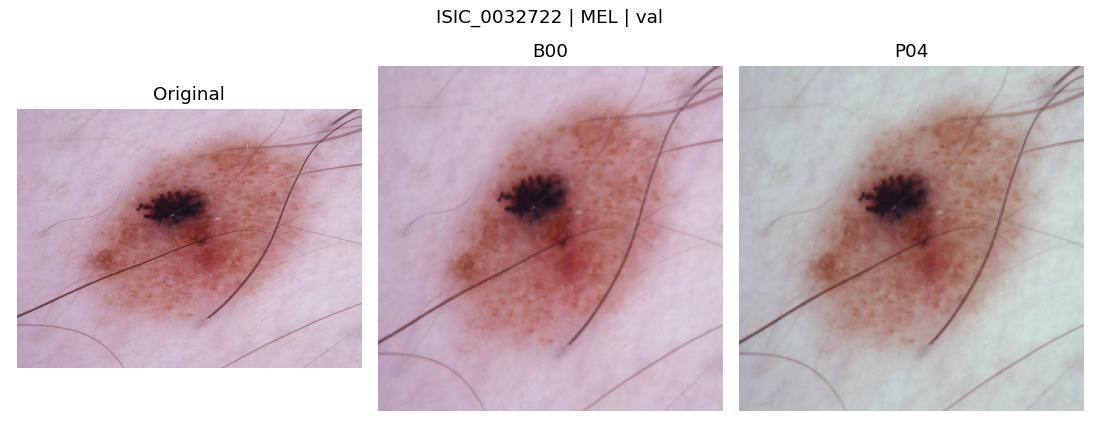

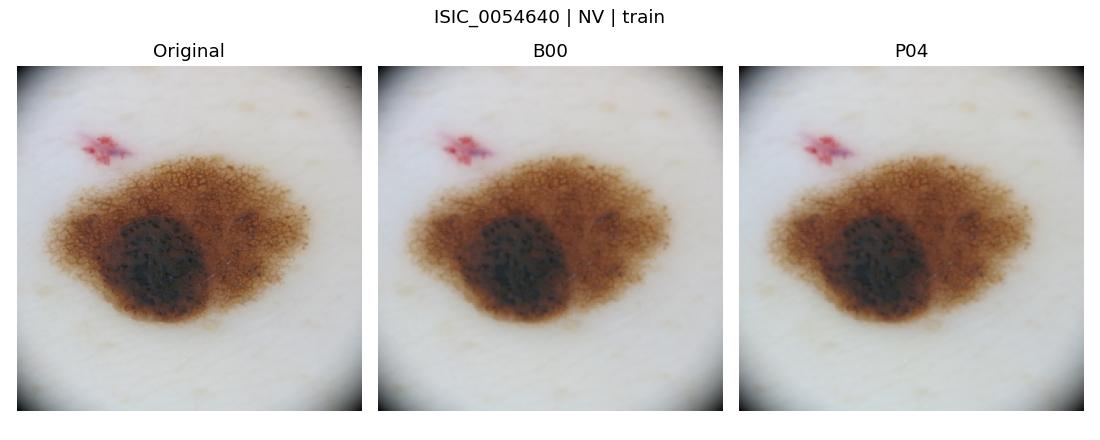

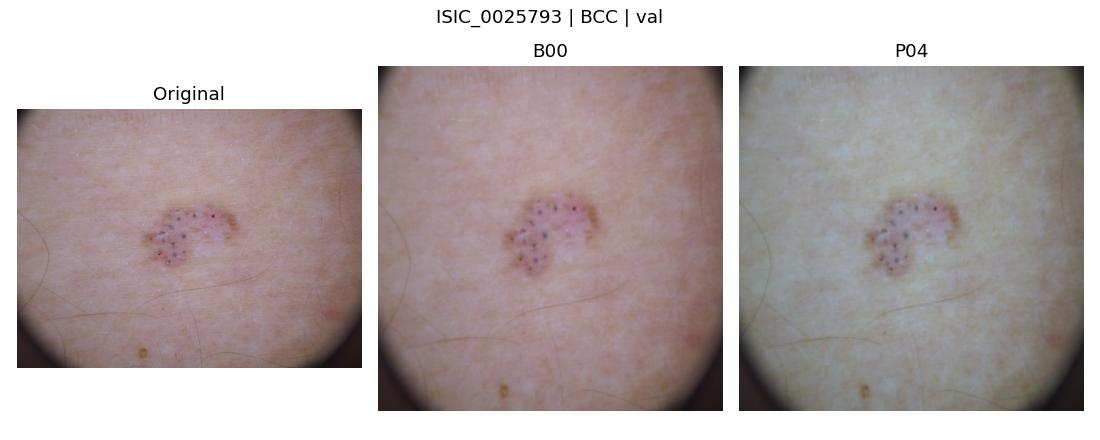

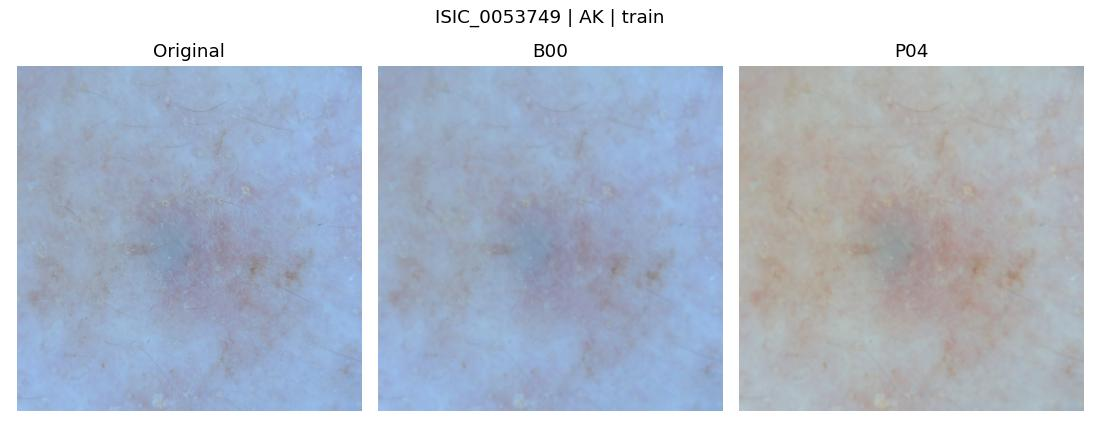

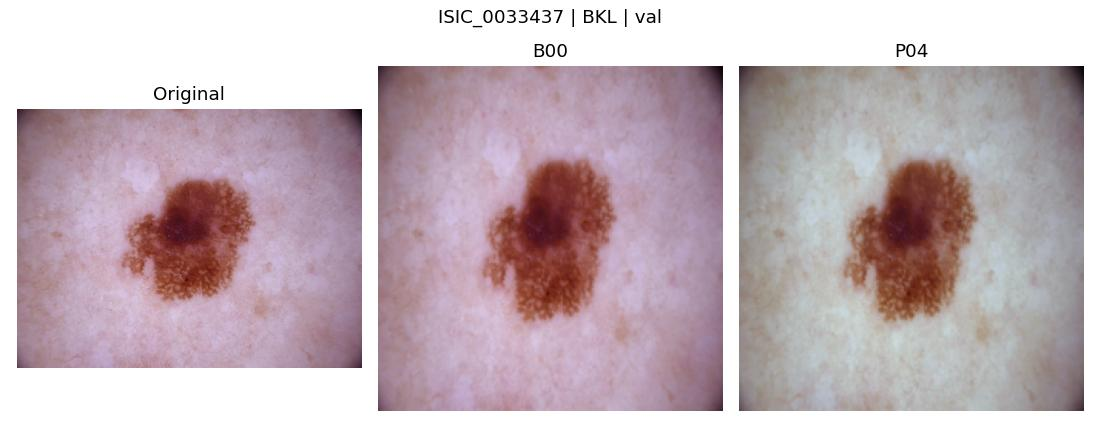

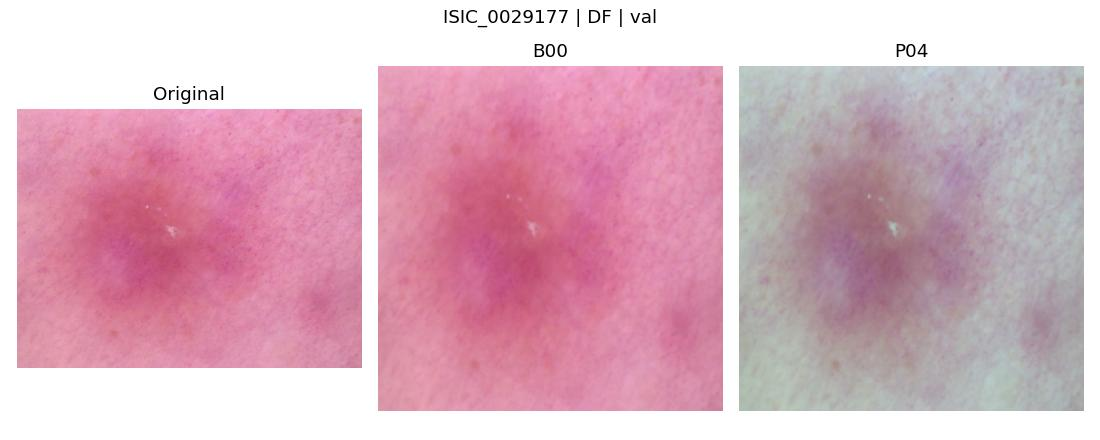

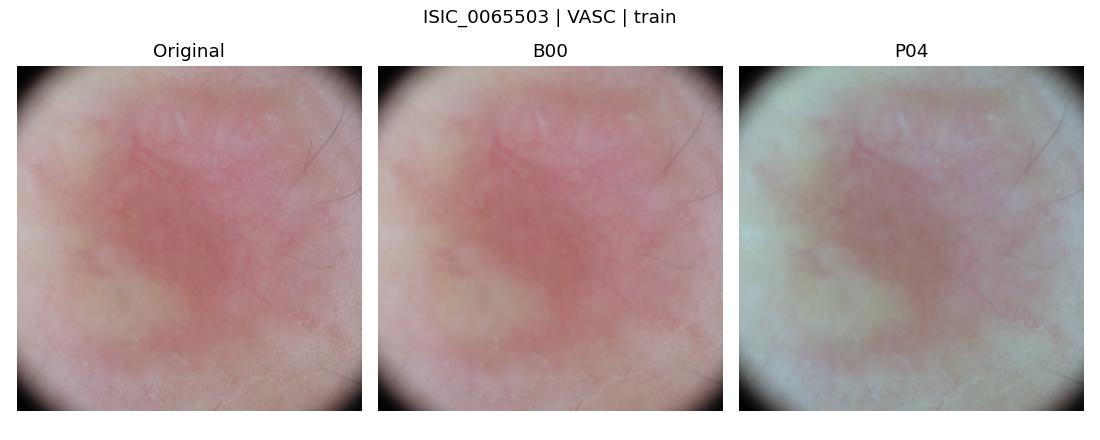

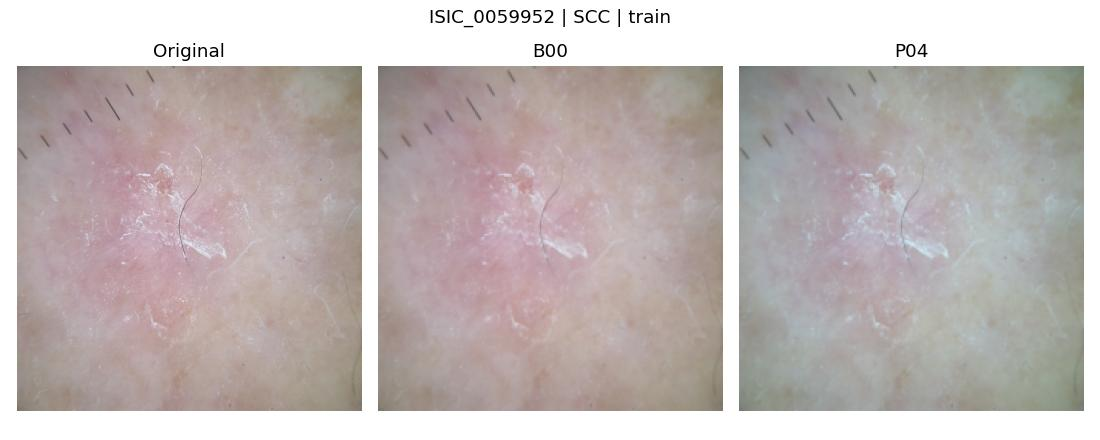

Preview: 59 ảnh. Xem before_after và overlays nếu có.


In [5]:
sheets=OUT/'before_after';sheets.mkdir()
overlays=OUT/'overlays';overlays.mkdir()
rows=[];qa=[]
for row in sample.itertuples(index=False):
    im=read_original(row);base,_=process(im,'B00')
    t=time.perf_counter();out,info=process(im,TRAIN_METHOD);ms=(time.perf_counter()-t)*1000
    a=np.asarray(out);assert a.shape==(224,224,3) and a.dtype==np.uint8
    rows.append({'image':row.image,'split':row.split,'label_name':row.label_name,'method':TRAIN_METHOD,'ms_transform_only':ms,
      'mae_vs_B00':float(np.abs(a.astype(float)-np.asarray(base).astype(float)).mean()),
      **{k:v for k,v in info.items() if k!='mask'}})
    fig,axs=plt.subplots(1,3,figsize=(10,4))
    for ax,img,title in zip(axs,[im,base,out],['Original','B00',TRAIN_METHOD+(' fallback' if info['fallback'] else '')]):
        ax.imshow(img);ax.set_title(title);ax.axis('off')
    fig.suptitle(f'{row.image} | {row.label_name} | {row.split}');fig.tight_layout()
    fig.savefig(sheets/f'{row.label_name}_{row.image}.jpg',dpi=110);plt.close(fig)
    if info['mask'] is not None or info['crop_box'] is not None:
        ov=im.copy();ov.thumbnail((900,900));draw=ImageDraw.Draw(ov)
        if info['crop_box'] is not None:
            x0,y0,x1,y1=info['crop_box'];draw.rectangle((x0*ov.width/im.width,y0*ov.height/im.height,x1*ov.width/im.width,y1*ov.height/im.height),outline='red',width=3)
        if info['mask'] is not None:
            mask=Image.fromarray(info['mask']).resize(ov.size,Image.Resampling.NEAREST)
            arr=np.array(ov);m=np.array(mask)>0;arr[m]=(0.5*arr[m]+0.5*np.array([255,0,0])).astype(np.uint8);ov=Image.fromarray(arr)
        ov.save(overlays/f'{row.image}.png')
    qa.append({'image':row.image,'label_name':row.label_name,'method':TRAIN_METHOD,'reviewed':False,'decision':'pending','notes':''})
pd.DataFrame(rows).to_csv(OUT/'technical_audit.csv',index=False)
pd.DataFrame(qa).to_csv(OUT/'visual_review_template.csv',index=False)
for label in LABELS:
    display(Image.open(next(sheets.glob(label+'_*.jpg'))))
print('Preview:',len(rows),'ảnh. Xem before_after và overlays nếu có.')


In [6]:
if REQUEST_TRAIN and TRAIN_METHOD in ['P03','P10'] and len(HIGH_RISK_REVIEW_NOTE.strip())<50:
    raise ValueError('P03/P10 cần kiểm tra ảnh/mask và ghi HIGH_RISK_REVIEW_NOTE ít nhất 50 ký tự trước khi bật train; không tự gán đạt QA.')
RUN_TRAIN=bool(REQUEST_TRAIN)
if RUN_TRAIN and not KAGGLE:raise ValueError('Train trên Kaggle GPU để giữ môi trường so sánh.')
(OUT/'run_intent.json').write_text(json.dumps({'requested_train':REQUEST_TRAIN,'review_note':HIGH_RISK_REVIEW_NOTE,'clinical_validation':False,'mode':'exploratory','mask_review_required':TRAIN_METHOD in ['P03','P10']},ensure_ascii=False,indent=2))
result_columns=['run_id','method','backbone','protocol_sha256','seed','best_epoch','epochs_completed','val_macro_f1','val_balanced_accuracy','val_accuracy']+['recall_'+x for x in LABELS]+['train_seconds','decision','notes']
print('Train:',RUN_TRAIN,'Method:',TRAIN_METHOD)


Train: True Method: P04


In [7]:
if RUN_TRAIN:
    import os, random, warnings, gc
    import torch, torchvision
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms, models
    from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score, f1_score, accuracy_score, recall_score
    from concurrent.futures import ThreadPoolExecutor
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    assert device.type=='cuda','Bật GPU; không tự chạy train trên CPU.'
    assert BACKBONE=='resnet18' and (SEED,EPOCHS,PATIENCE,BATCH_SIZE,IMG_SIZE,NUM_WORKERS)==(42,16,4,32,224,2)
    # Validate every dev image before training, not only QA examples.
    def verify_row(row):
        if hashlib.sha256(Path(row.path).read_bytes()).hexdigest()!=row.file_sha256:raise ValueError('Ảnh khác nguồn '+row.image)
    with ThreadPoolExecutor(max_workers=4) as pool:list(pool.map(verify_row,catalog.itertuples(index=False)))
    train=catalog[catalog.split=='train'].copy().reset_index(drop=True)
    val=catalog[catalog.split=='val'].copy().reset_index(drop=True)
    parts={'train':train,'val':val}
    torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
    def reset_seed():
        random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
        if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
    reset_seed()
    (OUT/'train_environment.json').write_text(json.dumps({'torch':str(torch.__version__),'torchvision':str(torchvision.__version__),'sklearn':__import__('sklearn').__version__,'GPU':torch.cuda.get_device_name(0)},indent=2))
    train_tf=transforms.Compose([
        FixedPreprocess(TRAIN_METHOD),transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),transforms.RandomRotation(20),
        transforms.ToTensor(),transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
    eval_tf=transforms.Compose([
        FixedPreprocess(TRAIN_METHOD),transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
    
    class SkinData(Dataset):
        def __init__(self,df,transform):self.df=df.reset_index(drop=True);self.transform=transform
        def __len__(self):return len(self.df)
        def __getitem__(self,i):
            row=self.df.iloc[i]
            with Image.open(row.path) as im:x=self.transform(im.convert('RGB'))
            return x,int(row.label)
    
    def seed_worker(worker_id):
        worker_seed=torch.initial_seed()%2**32
        random.seed(worker_seed);np.random.seed(worker_seed)
    
    def make_loaders():
        generator=torch.Generator().manual_seed(SEED)
        return {name:DataLoader(SkinData(part,train_tf if name=='train' else eval_tf),
                 batch_size=BATCH_SIZE,shuffle=(name=='train'),num_workers=NUM_WORKERS,
                 pin_memory=(device.type=='cuda'),worker_init_fn=seed_worker,
                 generator=generator if name=='train' else None)
                 for name,part in parts.items()}
    
    counts=np.bincount(train.label,minlength=len(LABELS))
    assert np.all(counts>0)
    weights=len(train)/(len(LABELS)*counts.astype(float))
    weights/=weights.mean()
    class_weights=torch.tensor(weights,dtype=torch.float32,device=device)
    print('Train counts:',dict(zip(LABELS,counts.tolist())))
    print('Class weights:',dict(zip(LABELS,np.round(weights,3).tolist())))
    
    def make_model(name,pretrained):
        if name=='resnet18':
            model=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
            model.fc=nn.Linear(model.fc.in_features,len(LABELS))
        elif name=='efficientnet_b0':
            model=models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
            model.classifier[1]=nn.Linear(model.classifier[1].in_features,len(LABELS))
        else:raise ValueError(name)
        return model
    
    def metrics(y,prob):
        pred=prob.argmax(1)
        return {'accuracy':float(accuracy_score(y,pred)),
                'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
                'macro_f1':float(f1_score(y,pred,labels=list(range(8)),average='macro',zero_division=0)),
                'macro_recall':float(recall_score(y,pred,labels=list(range(8)),average='macro',zero_division=0))}
    @torch.no_grad()
    def predict(model,loader,weight_for_loss=None):
        model.eval(); ys=[]; probs=[];weighted_sum=0.;denominator=0.
        for images,y in loader:
            images,y=images.to(device,non_blocking=True),y.to(device,non_blocking=True)
            logits=model(images)
            if weight_for_loss is not None:
                weighted_sum+=nn.functional.cross_entropy(
                    logits,y,weight=weight_for_loss,reduction='sum').item()
                denominator+=weight_for_loss[y].sum().item()
            ys.append(y.cpu().numpy())
            probs.append(logits.softmax(1).cpu().numpy())
        return np.concatenate(ys),np.concatenate(probs),(
            weighted_sum/denominator if weight_for_loss is not None else None)
    
    def train_one(name):
        reset_seed()
        loaders=make_loaders()
        try:model=make_model(name,pretrained=True).to(device)
        except Exception as err:
            raise RuntimeError(f'Không tải được ImageNet weights của {name}; bật Kaggle Internet. '
                               'Không huấn luyện random weights.') from err
        model_dir=OUT/name
        model_dir.mkdir(parents=True,exist_ok=False)
        opt=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
        sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=EPOCHS)
        best=-1.;best_epoch=0;bad=0;history=[];started=time.time()
        checkpoint_path=model_dir/('best_'+name+'.pt')
        for epoch in range(EPOCHS):
            model.train();weighted_sum=0.;denom=0.
            for images,y in loaders['train']:
                images,y=images.to(device,non_blocking=True),y.to(device,non_blocking=True)
                opt.zero_grad(set_to_none=True)
                logits=model(images)
                sum_loss=nn.functional.cross_entropy(logits,y,weight=class_weights,reduction='sum')
                norm=class_weights[y].sum()
                loss=sum_loss/norm
                if not torch.isfinite(loss):raise RuntimeError('Loss không hữu hạn.')
                loss.backward();opt.step()
                weighted_sum+=sum_loss.detach().item();denom+=norm.item()
            sched.step()
            vy,vp,vl=predict(model,loaders['val'],class_weights)
            vm=metrics(vy,vp)
            record={'epoch':epoch+1,'train_loss':weighted_sum/denom,'val_loss':vl,
                    **{'val_'+k:v for k,v in vm.items()}}
            history.append(record)
            pd.DataFrame(history).to_csv(model_dir/'history.csv',index=False)
            print(f'{name} epoch {epoch+1:02d}: train loss={record["train_loss"]:.4f}; '
                  f'val loss={vl:.4f}; val macro-F1={vm["macro_f1"]:.4f}',flush=True)
            if vm['macro_f1']>best+1e-5:
                best=vm['macro_f1'];best_epoch=epoch+1;bad=0
                torch.save({'state_dict':model.state_dict(),'architecture':name,
                            'labels':LABELS,'epoch':best_epoch,'seed':SEED,
                            'image_size':IMG_SIZE,'val_macro_f1':best},checkpoint_path)
            else:
                bad+=1
                if bad>=PATIENCE:
                    print('Early stopping:',name);break
        ck=torch.load(checkpoint_path,map_location=device,weights_only=True)
        model.load_state_dict(ck['state_dict'],strict=True)
        vy,vp,vl=predict(model,loaders['val'],class_weights)
        assert abs(metrics(vy,vp)['macro_f1']-best)<2e-5
        predictions=val[['image','group','label_name','file_sha256']].rename(
            columns={'label_name':'true_label'}).copy()
        predictions['pred_label']=[LABELS[i] for i in vp.argmax(1)]
        for i,label in enumerate(LABELS):predictions['p_'+label]=vp[:,i]
        predictions.to_csv(model_dir/'val_predictions.csv',index=False)
        (model_dir/'val_metrics.json').write_text(json.dumps(
            {'model':name,'best_epoch':best_epoch,'val_metrics':metrics(vy,vp),
             'val_loss':vl,'epochs_completed':len(history),
             'seconds':round(time.time()-started,1)},ensure_ascii=False,indent=2),encoding='utf-8')
        model.cpu();del model,opt,sched,loaders
        gc.collect()
        if device.type=='cuda':torch.cuda.empty_cache()
        return ck['epoch'],vy,vp,checkpoint_path
    
    epoch,y,p,checkpoint=train_one(BACKBONE)
    report=classification_report(y,p.argmax(1),labels=list(range(8)),target_names=LABELS,output_dict=True,zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT/'val_per_class_report.csv')
    pd.DataFrame(confusion_matrix(y,p.argmax(1),labels=list(range(8))),index=LABELS,columns=LABELS).to_csv(OUT/'val_confusion_matrix.csv')
    meta=json.loads((OUT/BACKBONE/'val_metrics.json').read_text());met=meta['val_metrics']
    record={'run_id':OUT.name,'method':TRAIN_METHOD,'backbone':BACKBONE,'protocol_sha256':PROTOCOL_SHA,'seed':SEED,'best_epoch':epoch,'epochs_completed':meta['epochs_completed'],'val_macro_f1':met['macro_f1'],'val_balanced_accuracy':met['balanced_accuracy'],'val_accuracy':met['accuracy'],'train_seconds':meta['seconds'],'decision':'pending','notes':'single seed; validation only'}
    record.update({'recall_'+x:report[x]['recall'] for x in LABELS})
    pd.DataFrame([record],columns=result_columns).to_csv(OUT/'result.csv',index=False)
    # Bind checkpoint to transform/split without rewriting its historical training format.
    (OUT/BACKBONE/'preprocessing_protocol.json').write_text(json.dumps({'method':TRAIN_METHOD,'protocol_sha256':PROTOCOL_SHA,**PROTOCOL},indent=2))
else:
    print('Chỉ QA; chưa tạo metrics hoặc checkpoint mới.')


Train counts: {'MEL': 2721, 'NV': 7689, 'BCC': 2006, 'AK': 493, 'BKL': 1573, 'DF': 152, 'VASC': 161, 'SCC': 345}
Class weights: {'MEL': 0.152, 'NV': 0.054, 'BCC': 0.206, 'AK': 0.839, 'BKL': 0.263, 'DF': 2.72, 'VASC': 2.568, 'SCC': 1.198}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


resnet18 epoch 01: train loss=1.3502; val loss=1.2645; val macro-F1=0.4290
resnet18 epoch 02: train loss=1.0251; val loss=1.1957; val macro-F1=0.4218
resnet18 epoch 03: train loss=0.8575; val loss=1.1485; val macro-F1=0.4787
resnet18 epoch 04: train loss=0.7602; val loss=1.1253; val macro-F1=0.5080
resnet18 epoch 05: train loss=0.6641; val loss=1.2721; val macro-F1=0.5156
resnet18 epoch 06: train loss=0.5443; val loss=1.2593; val macro-F1=0.5303
resnet18 epoch 07: train loss=0.4733; val loss=1.3255; val macro-F1=0.5501
resnet18 epoch 08: train loss=0.4488; val loss=1.4192; val macro-F1=0.5331
resnet18 epoch 09: train loss=0.3548; val loss=1.3542; val macro-F1=0.5240
resnet18 epoch 10: train loss=0.2908; val loss=1.4401; val macro-F1=0.5602
resnet18 epoch 11: train loss=0.2524; val loss=1.5389; val macro-F1=0.5710
resnet18 epoch 12: train loss=0.2181; val loss=1.5848; val macro-F1=0.5888
resnet18 epoch 13: train loss=0.1866; val loss=1.6099; val macro-F1=0.5931
resnet18 epoch 14: train 

In [8]:
if RUN_TRAIN:
    candidate=pd.read_csv(OUT/'resnet18'/'val_predictions.csv')
    assert candidate.image.is_unique and set(candidate.image)==set(baseline_predictions.image)
    paired=baseline_predictions[['image','true_label','pred_label']].merge(candidate[['image','true_label','pred_label']],on='image',suffixes=('_B00','_new'),validate='one_to_one')
    assert paired.true_label_B00.eq(paired.true_label_new).all()
    c0=paired.true_label_B00.eq(paired.pred_label_B00);c1=paired.true_label_new.eq(paired.pred_label_new)
    paired['transition']=np.select([c0&c1,c0&~c1,~c0&c1],['right_to_right','right_to_wrong','wrong_to_right'],default='wrong_to_wrong')
    paired.to_csv(OUT/'paired_B00_candidate.csv',index=False)
    comparison=[]
    for tag,d in [('B00',baseline_predictions),(TRAIN_METHOD,candidate)]:
        comparison.append({'method':tag,'n':len(d),'macro_f1':f1_score(d.true_label,d.pred_label,labels=LABELS,average='macro',zero_division=0),
          'accuracy':accuracy_score(d.true_label,d.pred_label),'balanced_accuracy':balanced_accuracy_score(d.true_label,d.pred_label)})
    table=pd.DataFrame(comparison);table.to_csv(OUT/'comparison_B00_candidate.csv',index=False);display(table)
    h=pd.read_csv(OUT/'resnet18'/'history.csv');fig,axs=plt.subplots(1,2,figsize=(11,4))
    axs[0].plot(h.epoch,h.train_loss,label='train weighted CE');axs[0].plot(h.epoch,h.val_loss,label='val weighted CE')
    axs[1].plot(h.epoch,h.val_macro_f1,label=TRAIN_METHOD+' val macro-F1');axs[1].axhline(table.iloc[0].macro_f1,color='gray',linestyle='--',label='B00 best')
    for ax in axs:ax.legend();ax.grid(alpha=.2);ax.set_xlabel('Epoch')
    fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=140);plt.close(fig)
else:
    print('Chỉ preview: chưa có điểm phân loại mới. Gửi ZIP để xem mask/ảnh trước khi quyết định train.')


,method,n,macro_f1,accuracy,balanced_accuracy
0,B00,5102,0.602765,0.695414,0.639428
1,P04,5102,0.605442,0.718346,0.638485


In [9]:
archive=OUT.parent/(OUT.name+'.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and p.suffix!='.pt':z.write(p,p.relative_to(OUT))
print('Gửi lại ZIP này:',archive)


Gửi lại ZIP này: /kaggle/working/screen_P04_20261003_171301_733709.zip
